# 03c - Cenários esperado, LI e LS com o ECMWF

Continuação do `03b` (lê `data/processed/backtest_ecmwf.pkl`). Mesma regra de vazamento: deck do mês M com a rodada do ECMWF
de M (D031), k = 15 e peso igual (D029), σ só com erros de meses já encerrados na data do deck. Seções 9.3 a 9.5 de
`docs/metodologia.md`.

1. σ por grupo de horizonte (M+1–3 / M+4–6) × σ único
2. Erros de M+4 a M+6: GSF ou preço? (diagnóstico com valores reais, não é método de previsão)
3. Trajetórias com o ECMWF e comparação com a Dcide
4. Cenários LI / LS: três formas e cobertura da faixa
5. Faixa de bandeiras e trajetórias dos cenários; dados da página de avaliação (`reports/pagina/`)

In [1]:
import json

import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy.stats import norm

from forecast_bandeiras import backtest, ecmwf, graficos, load, newave, regra

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 220)
base = pd.read_parquet(load.DATA_PROCESSED / "base_mensal.parquet")
base.index = base.index.to_period("M")
base["cor_oficial"] = [c if isinstance(c, str) else r for c, r in zip(base.cor_boletim, base.cor_regra)]
base["x_real"] = base.pld_gatilho_boletim * (1 - base.gsf_band_boletim).clip(lower=0)
# meses ainda sem bandeira real, para as previsões do deck mais recente (patamares só até dez/2026)
base = base.reindex(base.index.union(pd.period_range("2026-11", "2026-12", freq="M")))
ORD = ["Verde", "Amarela", "Vermelha 1", "Vermelha 2"]
NIVEL = {c: i for i, c in enumerate(ORD)}
AB = {"Verde": "Vd", "Amarela": "Am", "Vermelha 1": "V1", "Vermelha 2": "V2"}
K, MV = backtest.K_PADRAO, backtest.MEIA_VIDA_PADRAO

A = pd.read_pickle(load.DATA_PROCESSED / "backtest_ecmwf.pkl")["A: ECMWF média"].reset_index(drop=True)
oraculo = pd.read_pickle(load.DATA_PROCESSED / "backtest_ecmwf.pkl")["oráculo"].reset_index(drop=True)
decks = sorted(A.deck.unique())
preps = {dk: backtest.preparar_deck(dk.year, dk.month, base) for dk in decks}
len(decks)

16

## 1. σ por grupo de horizonte

σ único (todos os horizontes) × σ por grupo (M+1–3 / M+4–6). O acerto não muda (a cor exibida é a da média); muda a
distribuição. Brier: soma dos quadrados entre a probabilidade e o resultado (0 = perfeito).

In [2]:
def avaliar_sigma(p, por_grupo):
    linhas = []
    for r in p.itertuples():
        hs = backtest.grupo_horizonte(r.h) if por_grupo else range(1, 7)
        s, _ = backtest.sigma_disponivel(p, r.deck, horizontes=hs)
        if np.isnan(s):
            s, _ = backtest.sigma_disponivel(p, r.deck)
        if np.isnan(s):
            continue
        pr = newave.probabilidade_calibrada(r.x_medio, s, r.gsf_medio)
        obs = np.array([float(c == r.cor_oficial) for c in ORD])
        linhas.append({"grupo": "M+1–3" if r.h <= 3 else "M+4–6", "sigma": s, "brier": ((pr.to_numpy() - obs) ** 2).sum(),
                       "confiança": pr[r.cor_media], "acerto": r.cor_media == r.cor_oficial, "prob. real": pr[r.cor_oficial]})
    return pd.DataFrame(linhas).groupby("grupo").mean()

pd.concat({"σ único": avaliar_sigma(A, False), "σ por grupo": avaliar_sigma(A, True)})

sigma  brier  confiança  acerto  prob. real
            grupo                                             
σ único     M+1–3 21.334  0.383      0.747   0.714       0.652
            M+4–6 21.054  0.725      0.687   0.400       0.438
σ por grupo M+1–3 15.714  0.377      0.785   0.714       0.675
            M+4–6 24.917  0.682      0.652   0.400       0.443

## 2. Erros de M+4 a M+6: GSF ou preço?

Em cada previsão, troca um insumo de cada vez pelo valor real e refaz a cor. Diagnóstico com dados do futuro.

In [3]:
def decompor(p):
    p = p.copy()
    p["grupo"] = np.where(p.h <= 3, "M+1–3", "M+4–6")
    p["cor_gsf_real"] = [regra.cor_bandeira(g, x) for g, x in zip(p.gsf_band_boletim, p.pld_medio)]
    p["cor_pld_real"] = [regra.cor_bandeira(g, x) for g, x in zip(p.gsf_medio, p.pld_gatilho_boletim)]
    return p, p.groupby("grupo").apply(lambda g: pd.Series({
        "n": len(g), "acerto": (g.cor_media == g.cor_oficial).mean(),
        "acerto c/ GSF real": (g.cor_gsf_real == g.cor_oficial).mean(),
        "acerto c/ PLD real": (g.cor_pld_real == g.cor_oficial).mean(),
        "|erro GSF|": (g.gsf_medio - g.gsf_band_boletim).abs().mean(),
        "|erro PLD|": (g.pld_medio - g.pld_gatilho_boletim).abs().mean()}), include_groups=False)

pA, tA = decompor(A)
display(pd.concat({"A: ECMWF média": tA, "oráculo": decompor(oraculo)[1]}))
e = pA[(pA.h >= 4) & (pA.cor_media != pA.cor_oficial)]
gsf_resolve, pld_resolve = e.cor_gsf_real == e.cor_oficial, e.cor_pld_real == e.cor_oficial
pd.Series(np.select([gsf_resolve & pld_resolve, gsf_resolve, pld_resolve], ["qualquer um", "só o GSF", "só o preço"],
                    "só os dois juntos"), index=e.index).value_counts()

n  acerto  acerto c/ GSF real  acerto c/ PLD real  |erro GSF|  |erro PLD|
               grupo                                                                               
A: ECMWF média M+1–3 46.000   0.717               0.717               0.913       0.038      82.797
               M+4–6 43.000   0.419               0.488               0.860       0.053      94.377
oráculo        M+1–3 46.000   0.696               0.717               0.913       0.039      81.275
               M+4–6 44.000   0.750               0.659               0.955       0.040      52.859

só o preço           14
qualquer um           5
só os dois juntos     4
só o GSF              2
Name: count, dtype: int64

## 3. Trajetórias com o ECMWF e comparação com a Dcide

Uma coluna por mês-alvo: ENA, GSF e PLD das 15 séries escolhidas pela trajetória do ECMWF (mesmas séries nas três linhas).
A Dcide só existe para os decks de jan e fev/2026; a cor da Dcide usa o GSF médio das séries com o preço da Dcide.

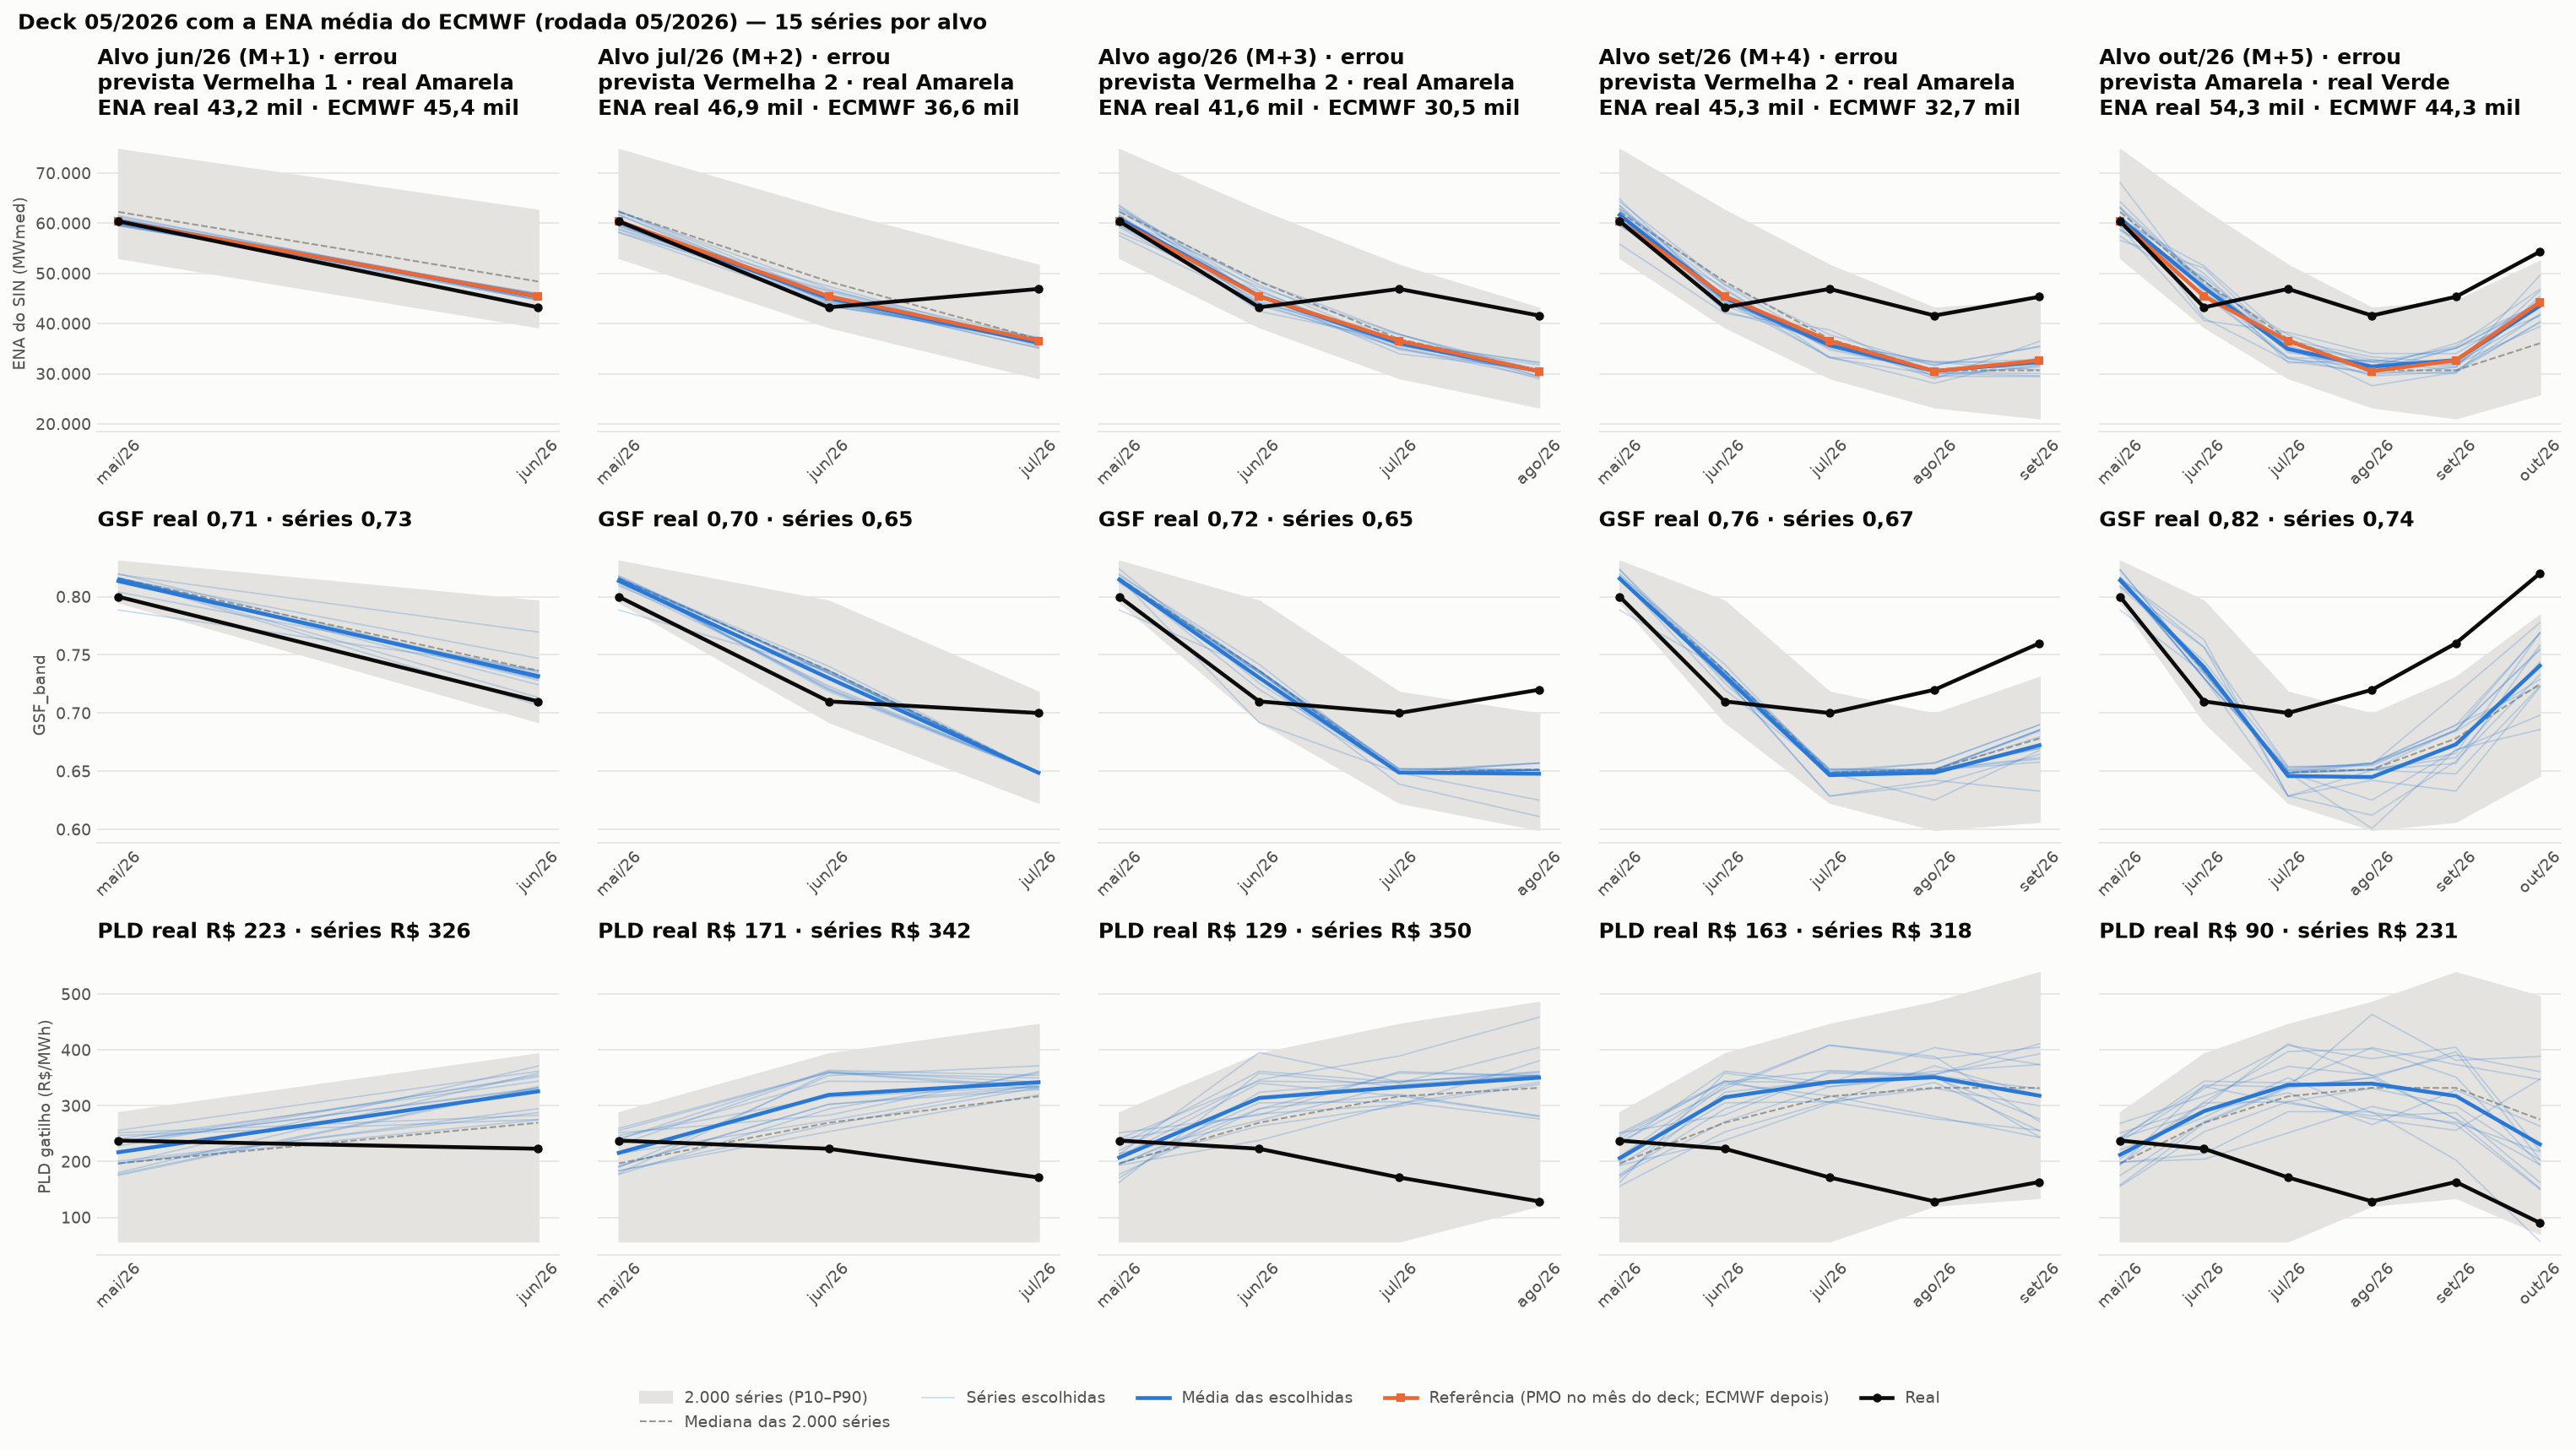

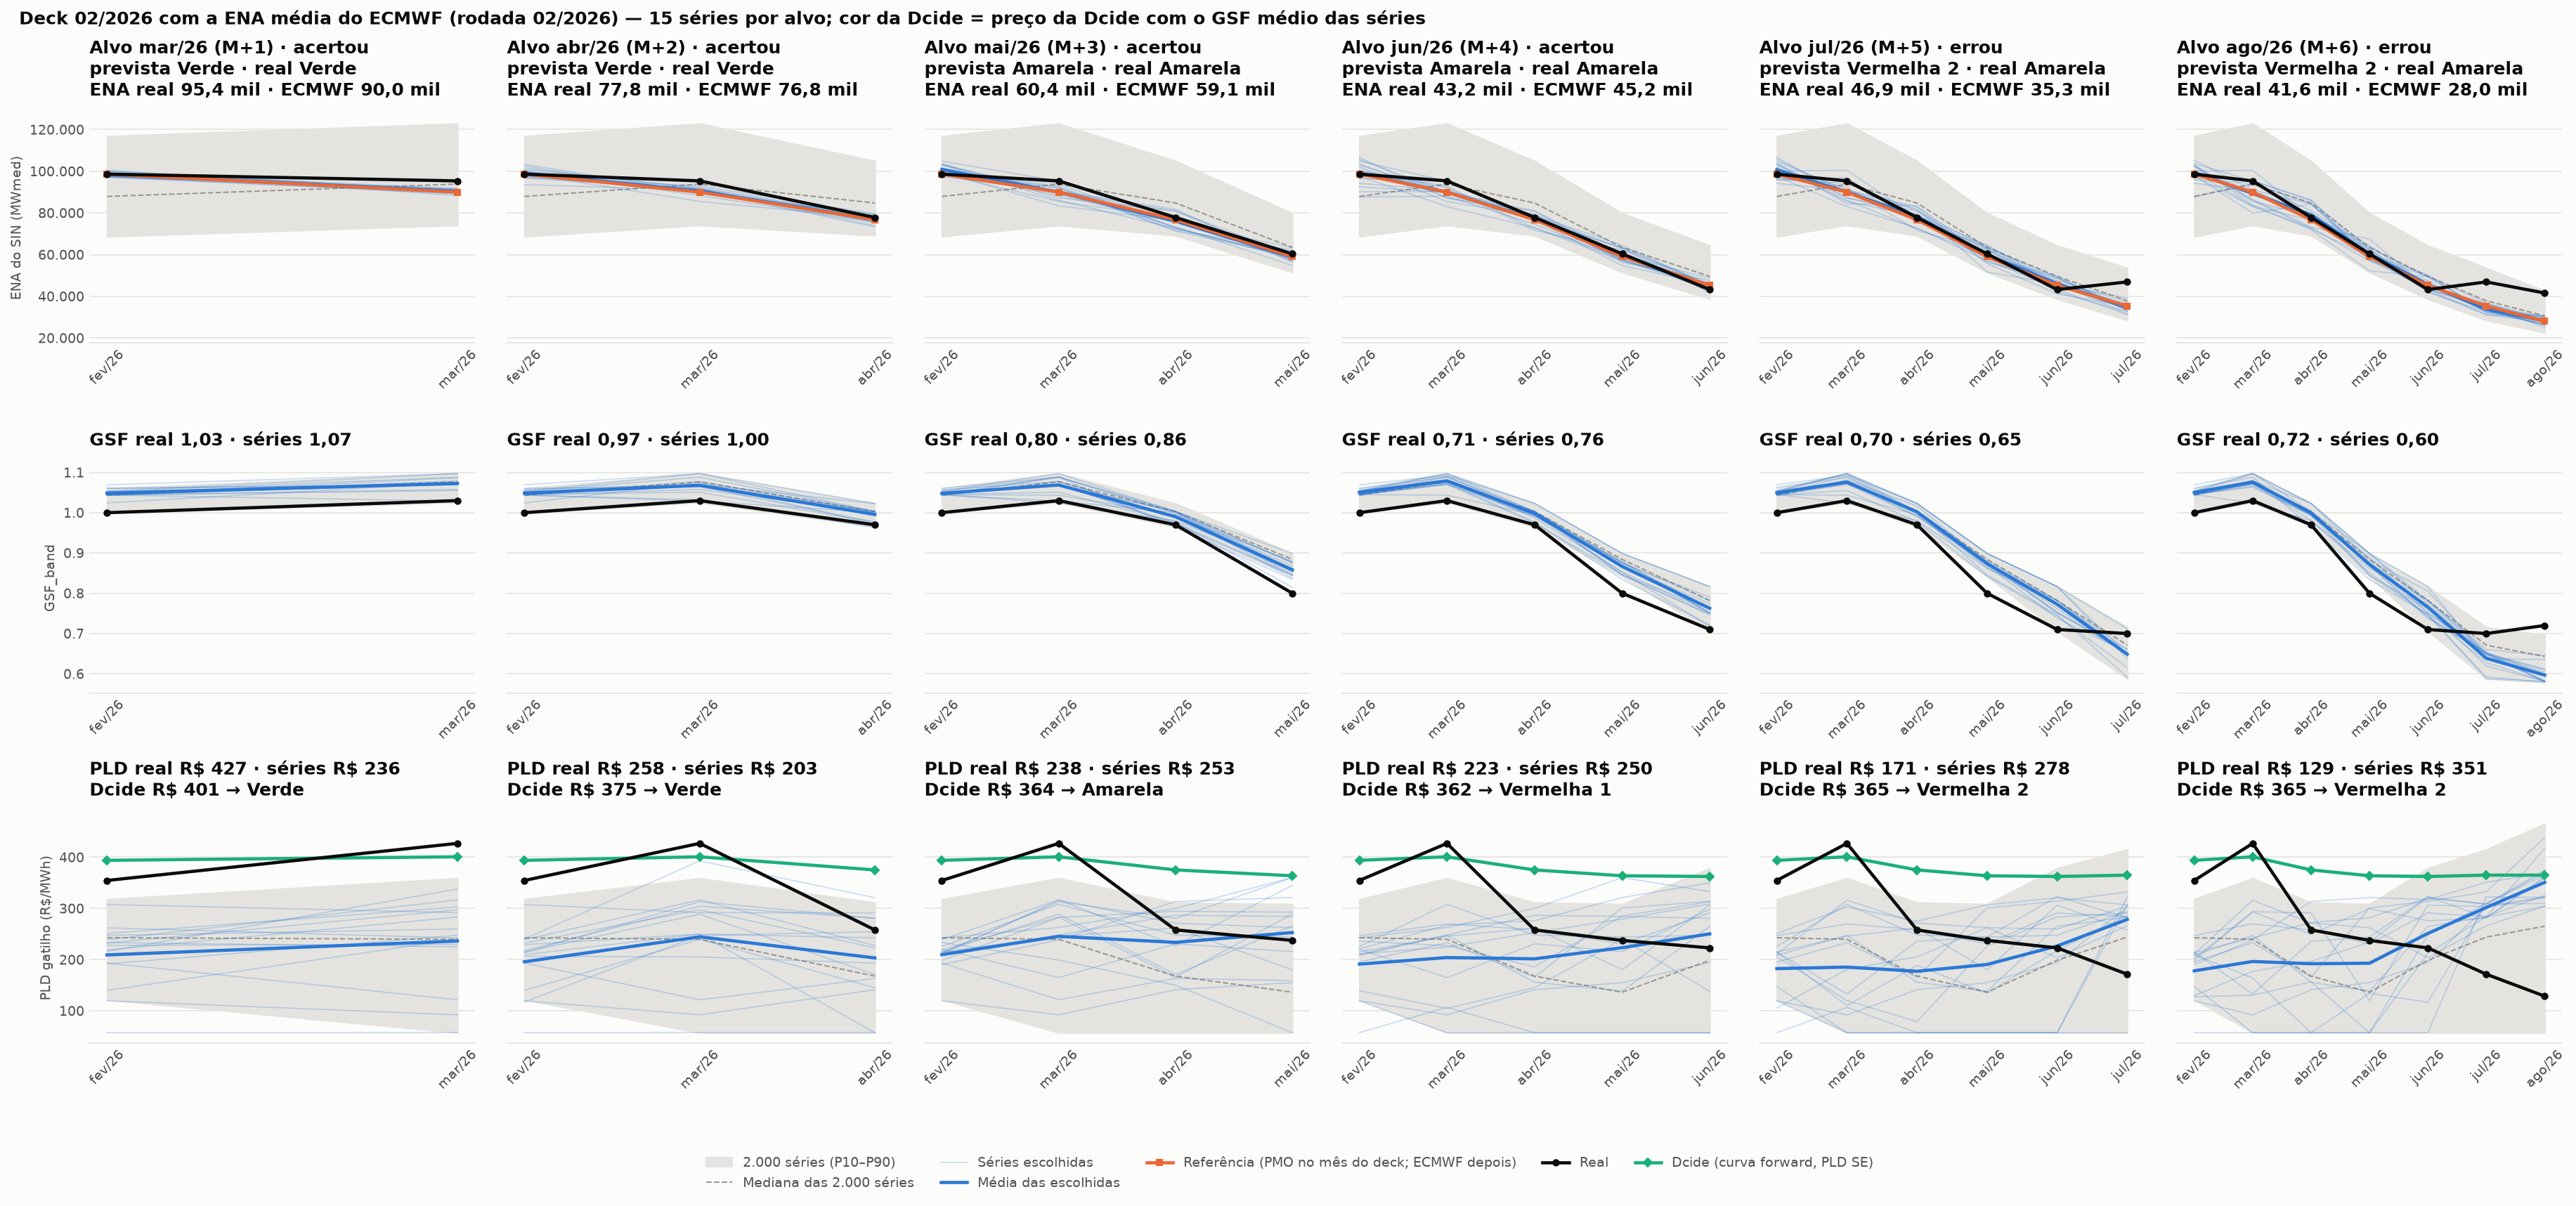

,deck,alvo,PLD real,PLD séries,PLD Dcide,cor séries,cor Dcide,cor real
0,2026-01,2026-02,354.650,150.582,298.010,Verde,Verde,Verde
1,2026-01,2026-03,427.080,167.089,308.260,Verde,Verde,Verde
2,2026-01,2026-04,258.010,217.869,266.480,Verde,Verde,Verde
3,2026-01,2026-05,237.580,146.300,267.480,Verde,Amarela,Amarela
4,2026-01,2026-06,222.920,136.747,273.410,Amarela,Amarela,Amarela
5,2026-01,2026-07,171.480,224.822,312.710,Vermelha 1,Vermelha 2,Amarela
6,2026-02,2026-03,427.080,236.351,400.860,Verde,Verde,Verde
7,2026-02,2026-04,258.010,203.308,375.210,Verde,Verde,Verde
8,2026-02,2026-05,237.580,252.866,363.770,Amarela,Amarela,Amarela
9,2026-02,2026-06,222.920,250.349,362.370,Amarela,Vermelha 1,Amarela


{'séries': 8, 'Dcide': 8}

In [4]:
def trajetoria(dk, dcide=None, pasta="trajetorias", prefixo="13_trajetorias_deck"):
    pr = preps[dk]
    ref = ecmwf.referencia_media(dk, base)
    r = A[A.deck == dk].set_index("alvo")
    alvos = list(r.index)
    esc = {a: backtest._escolher(pr, ref, a, K, MV) for a in alvos}
    cores = {a: (r.loc[a, "cor_media"], r.loc[a, "cor_oficial"]) for a in alvos}
    titulo = f"Deck {dk.month:02d}/{dk.year} com a ENA média do ECMWF (rodada {dk.month:02d}/{dk.year}) — 15 séries por alvo"
    if dcide is not None:
        titulo += "; cor da Dcide = preço da Dcide com o GSF médio das séries"
    return graficos.trajetorias_ecmwf(pr["ena"], pr["gsf"], pr["pld"], ref, base, esc, cores, titulo,
                                      f"ecmwf/{pasta}/{prefixo}_{dk.year}_{dk.month:02d}.png", dcide=dcide)

for dk in [pd.Period(p, "M") for p in ("2025-01", "2025-05", "2026-03", "2026-05")]:
    caminho = trajetoria(dk)
display(Image(caminho))

comparacao = []
for dk in [pd.Period("2026-01", "M"), pd.Period("2026-02", "M")]:
    dc = load.ler_dcide(dk.year, dk.month)
    dc.index = dc.index.to_period("M")
    caminho = trajetoria(dk, dc, "trajetorias_dcide", "14_trajetorias_dcide_deck")
    for r in A[A.deck == dk].itertuples():
        comparacao.append({"deck": dk, "alvo": r.alvo, "PLD real": r.pld_gatilho_boletim, "PLD séries": r.pld_medio,
                           "PLD Dcide": dc.get(r.alvo), "cor séries": r.cor_media,
                           "cor Dcide": regra.cor_bandeira(r.gsf_medio, dc.get(r.alvo)), "cor real": r.cor_oficial})
display(Image(caminho))
comp = pd.DataFrame(comparacao)
display(comp)
{c: int((comp[f"cor {c}"] == comp["cor real"]).sum()) for c in ("séries", "Dcide")}

## 4. Cenários LI / LS: três formas e cobertura

1. **Percentil mensal da ENA dos membros:** trajetória = P10 (LI, seco) e P90 (LS, úmido) da ENA do SIN dos 51 membros
   recentrados → 15 séries → cor. Faixa de 50%: P25 / P75.
2. **X por membro:** cada membro escolhe suas 15 séries; LI / LS = P90 / P10 do X entre os membros.
3. **σ por grupo:** X médio ± 1,28σ (80%) ou ± 0,67σ (50%).

Medida principal: X real dentro da faixa (contínua). A cor real dentro da faixa sai acima do nominal porque a cor é discreta.
Amostra comum: previsões com σ disponível (comparação entre métodos feita na mesma amostra: dentro da amostra).

In [5]:
QS = [0.1, 0.25, 0.75, 0.9]
linhas = []
for dk in decks:
    pr = preps[dk]
    mem = ecmwf.referencia_membros(dk, base)
    for alvo in [a for a in pr["alvos"] if 1 <= (a - dk).n <= 6 and a in mem.columns and a in set(A.alvo[A.deck == dk])]:
        lin = {"deck": dk, "alvo": alvo, "h": (alvo - dk).n}
        for q in QS:
            idx = backtest._escolher(pr, mem.quantile(q), alvo, K, MV)
            g, p = round(pr["gsf"].loc[idx, alvo].mean(), 2), pr["pld"].loc[idx, alvo].mean()
            lin[f"x_pct{int(q * 100)}"] = p * max(0.0, 1 - g)
        xs = []
        for _, ref in mem.iterrows():
            idx = backtest._escolher(pr, ref, alvo, K, MV)
            g, p = round(pr["gsf"].loc[idx, alvo].mean(), 2), pr["pld"].loc[idx, alvo].mean()
            xs.append(p * max(0.0, 1 - g))
        for q in QS:
            lin[f"x_mem{int(q * 100)}"] = np.quantile(xs, q)
        lin["ena_real"], lin["ena_p10"], lin["ena_p90"] = base.loc[alvo, "ena_sin"], mem[alvo].quantile(0.1), mem[alvo].quantile(0.9)
        linhas.append(lin)
C = pd.DataFrame(linhas).merge(A, on=["deck", "alvo", "h"])
C["sigma_g"] = [backtest.sigma_disponivel(A, d, horizontes=backtest.grupo_horizonte(h))[0] for d, h in zip(C.deck, C.h)]
for q in QS:
    C[f"x_sig{int(q * 100)}"] = (C.x_medio + norm.ppf(q) * C.sigma_g).clip(lower=0)

FAIXAS = {
    "1. percentil mensal da ENA": {"80%": ("x_pct90", "x_pct10"), "50%": ("x_pct75", "x_pct25")},
    "2. X por membro": {"80%": ("x_mem10", "x_mem90"), "50%": ("x_mem25", "x_mem75")},
    "3. σ por grupo": {"80%": ("x_sig10", "x_sig90"), "50%": ("x_sig25", "x_sig75")},
}
def nivel_x(x):
    return NIVEL[regra.cor_bandeira(0.0, x)]

def cobertura(D):
    out = {}
    for m, fx in FAIXAS.items():
        for nome, (lo, hi) in fx.items():
            a, b = np.minimum(D[lo], D[hi]), np.maximum(D[lo], D[hi])
            na, nb, nr = a.map(nivel_x), b.map(nivel_x), D.cor_oficial.map(NIVEL)
            out[(m, nome)] = {"X real na faixa": ((D.x_real >= a) & (D.x_real <= b)).mean(),
                              "cor real na faixa": ((nr >= na) & (nr <= nb)).mean(), "nº de cores": (nb - na + 1).mean()}
    return pd.DataFrame(out).T

amostra = C[C.sigma_g.notna()]
display(pd.concat({g: cobertura(D) for g, D in amostra.groupby(np.where(amostra.h <= 3, "M+1–3", "M+4–6"))}, axis=1))
((C.ena_real >= C.ena_p10) & (C.ena_real <= C.ena_p90)).groupby(np.where(C.h <= 3, "M+1–3", "M+4–6")).mean()

M+1–3                                         M+4–6                              
                               X real na faixa cor real na faixa nº de cores X real na faixa cor real na faixa nº de cores
1. percentil mensal da ENA 80%           0.760             0.960       1.880           0.750             1.000       2.900
                           50%           0.560             0.920       1.560           0.300             0.800       2.450
2. X por membro            80%           0.800             0.920       1.800           0.500             0.950       2.700
                           50%           0.480             0.920       1.440           0.150             0.600       2.100
3. σ por grupo             80%           0.840             0.920       1.560           0.450             0.850       2.450
                           50%           0.600             0.880       1.360           0.200             0.700       1.900

M+1–3   0.826
M+4–6   0.767
dtype: float64

## 5. Faixa de bandeiras e trajetórias dos cenários

Esperado (média `precip`), LI (P10 mensal da ENA dos membros) e LS (P90), forma 1. Probabilidade do esperado com σ por
grupo. Na faixa, ✗ no esperado = cor errada; no LI ou LS = cor real fora da faixa. Os dados alimentam a página de
avaliação (`reports/pagina/dados_faixa.json`).

In [6]:
def br(v, casas=0):
    return f"{v:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")

cenarios, registros = {}, []
for dk in decks:
    pr = preps[dk]
    refs = {"esp": ecmwf.referencia_media(dk, base), "li": ecmwf.referencia_quantil(dk, base, 0.1),
            "ls": ecmwf.referencia_quantil(dk, base, 0.9)}
    t = backtest.prever_cenarios(pr, refs)
    t = t[(t.h >= 1) & (t.h <= 6)]
    cenarios[dk] = (pr, refs, t)
    for r in t.itertuples():
        prob = backtest.probabilidade_por_grupo(A, dk, r.h, r.x_esp, r.gsf_esp)
        real = base.loc[r.alvo, "cor_oficial"]
        registros.append({"deck": str(dk), "alvo": str(r.alvo), "h": int(r.h), "real": real if isinstance(real, str) else None,
                          "esp": r.cor_esp, "li": r.cor_li, "ls": r.cor_ls,
                          "prob": "sem histórico para a probabilidade" if prob.isna().all()
                                  else " ".join(f"{AB[c]} {v:.0%}" for c, v in prob.items() if v >= 0.05),
                          "gp": f"GSF {br(r.gsf_esp, 2)} · R$ {br(r.pld_esp)}"})
F = pd.DataFrame(registros)
R = F[F.real.notna()]
dentro = [NIVEL[x.ls] <= NIVEL[x.real] <= NIVEL[x.li] for x in R.itertuples()]
display(R.assign(dentro=dentro).groupby(R.deck.str[:4]).agg(previsoes=("real", "size"),
        esperado_acerta=("esp", lambda s: int((s == R.loc[s.index, "real"]).sum())), dentro_LS_LI=("dentro", "sum")))
destino = load.RAIZ / "reports" / "pagina" / "dados_faixa.json"
destino.parent.mkdir(parents=True, exist_ok=True)
destino.write_text(json.dumps(registros, ensure_ascii=False))
destino

,previsoes,esperado_acerta,dentro_LS_LI
deck,,,
2025,59,37,55
2026,30,14,29


PosixPath('/Users/arthur/projects/forecast-bandeiras/reports/pagina/dados_faixa.json')

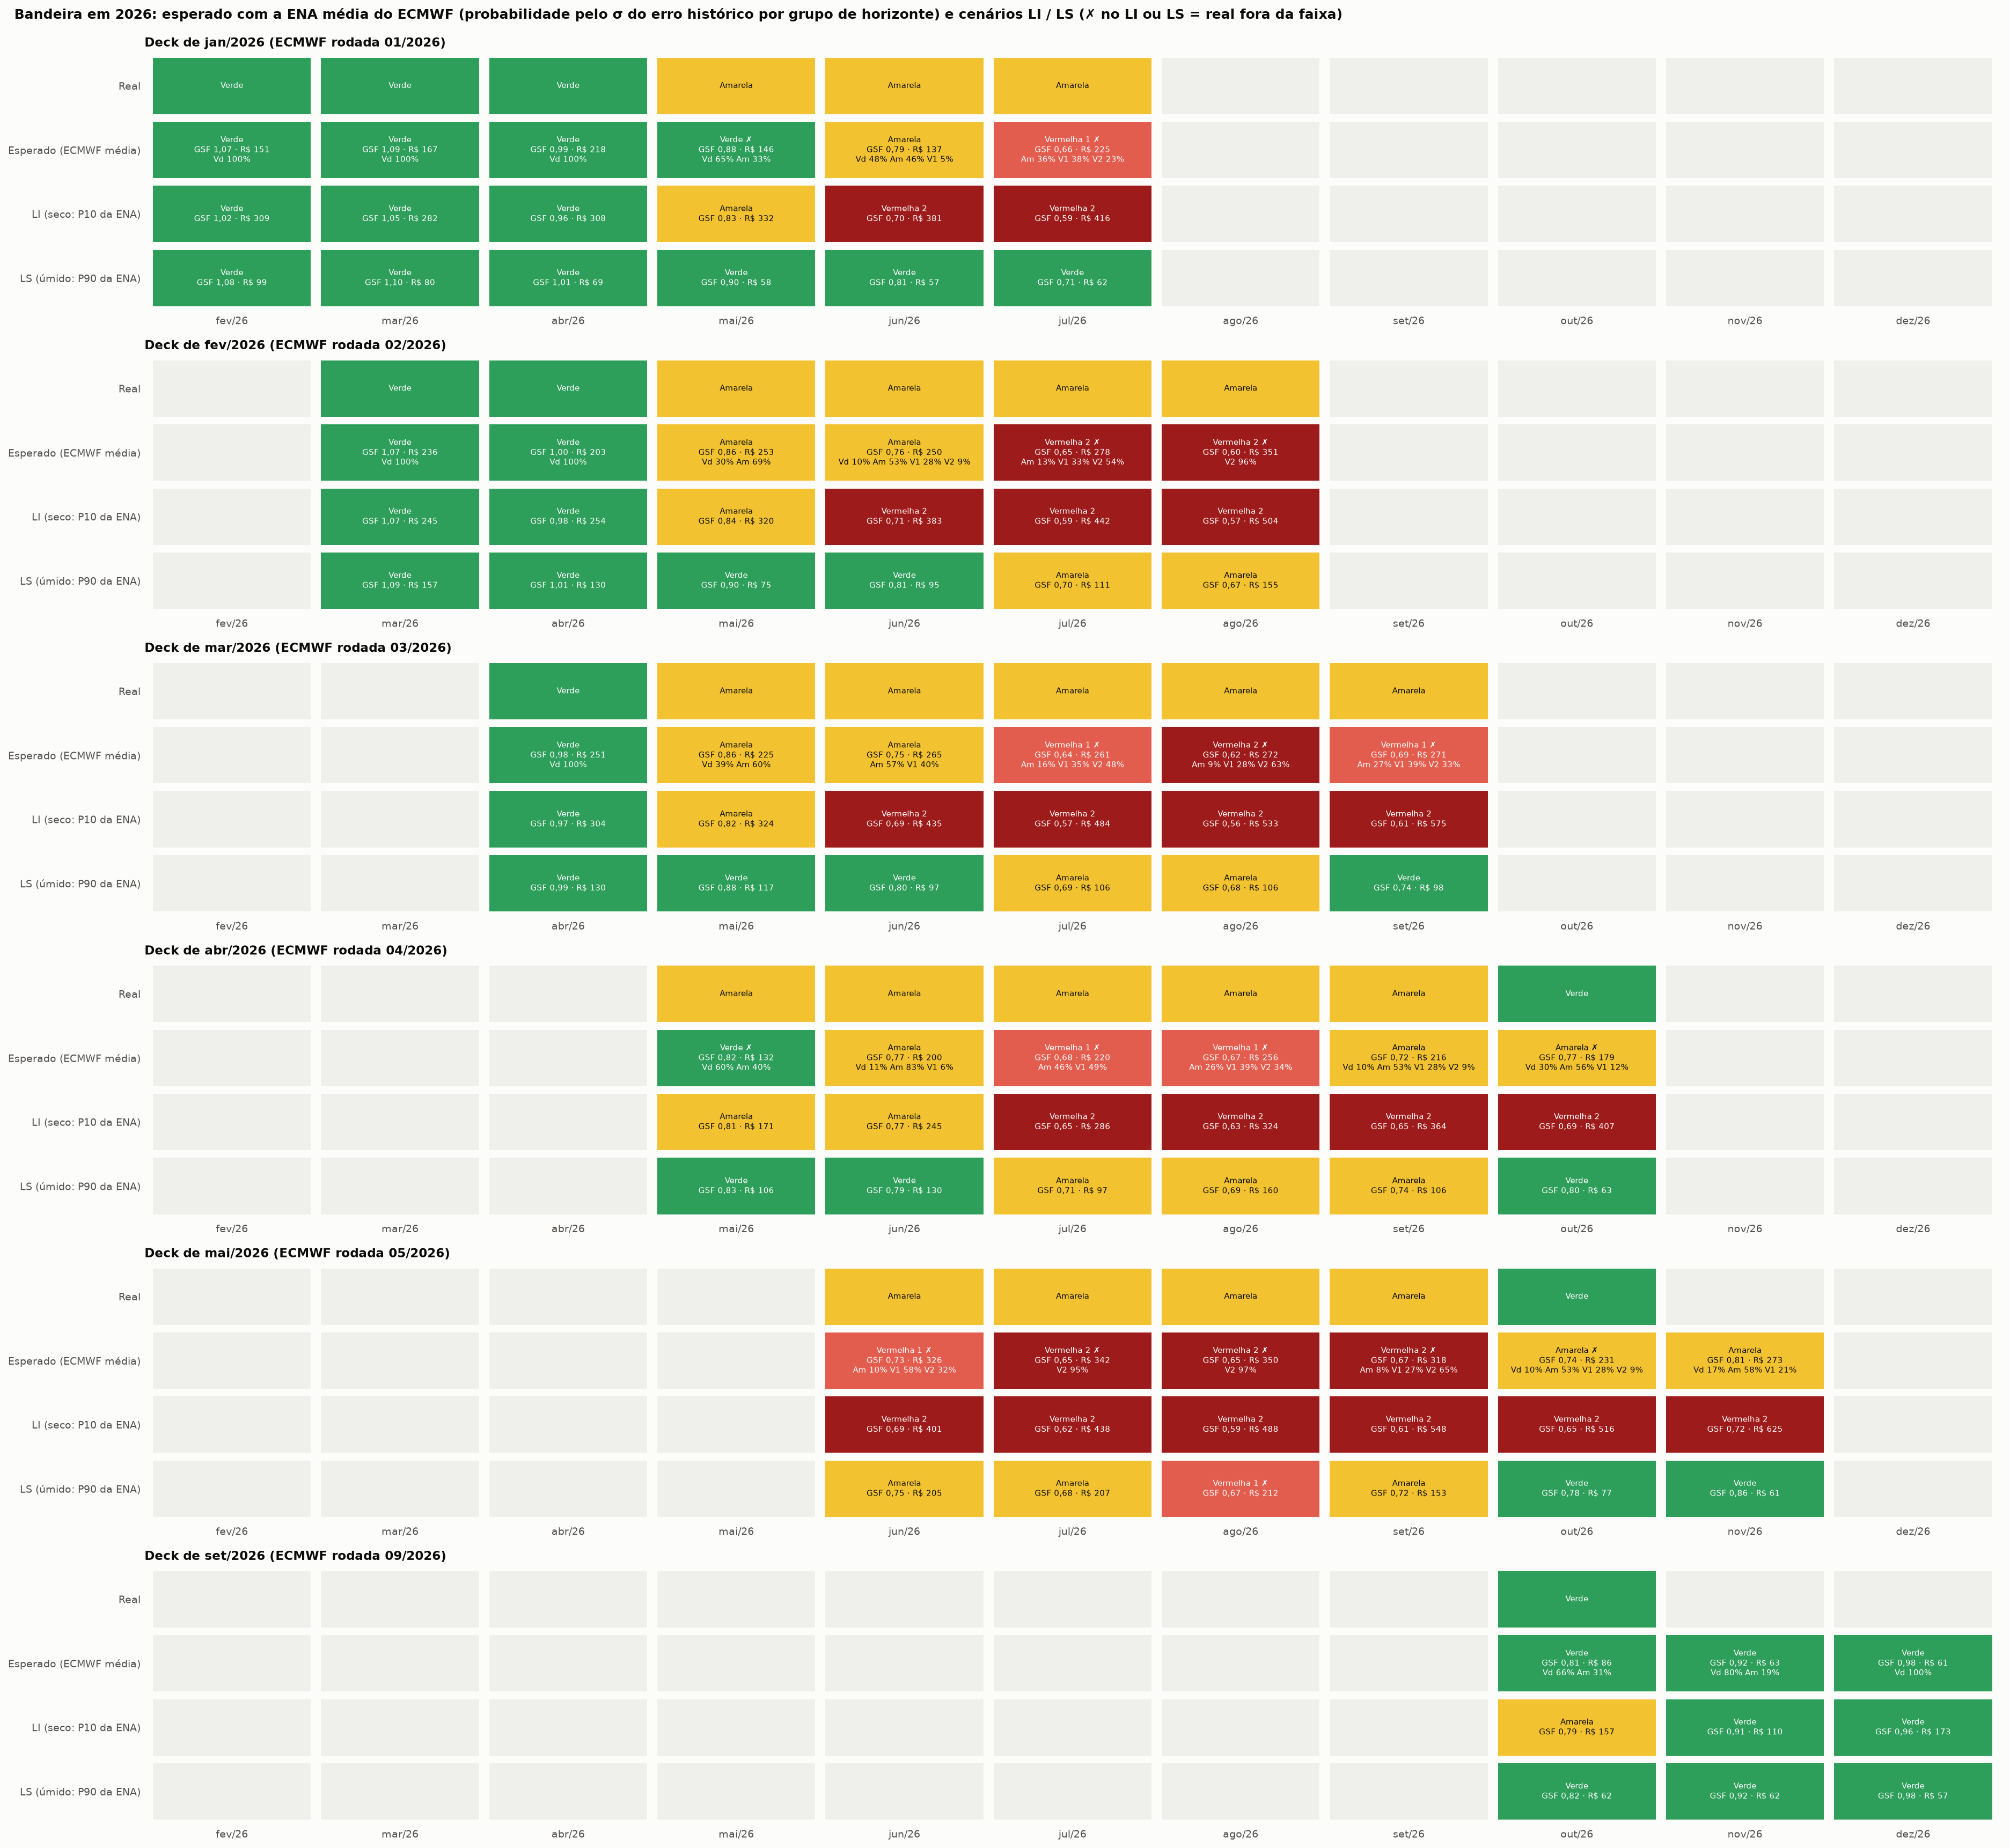

In [7]:
tabelas = {}
for dk in [d for d in decks if d.year == 2026]:
    t = cenarios[dk][2].set_index("alvo")
    f = F[F.deck == str(dk)].set_index(F.alvo[F.deck == str(dk)].map(lambda a: pd.Period(a, "M")))
    tabelas[f"Deck de {graficos.MESES[dk.month - 1]}/{dk.year} (ECMWF rodada {dk.month:02d}/{dk.year})"] = pd.DataFrame({
        "cor_real": f.real, "cor_esp": t.cor_esp, "cor_li": t.cor_li, "cor_ls": t.cor_ls,
        "txt_esp": [gp.replace("$", "\\$") + "\n" + pb for gp, pb in zip(f.gp, f.prob)],
        "txt_li": [f"GSF {br(g, 2)} · R\\$ {br(p)}" for g, p in zip(t.gsf_li, t.pld_li)],
        "txt_ls": [f"GSF {br(g, 2)} · R\\$ {br(p)}" for g, p in zip(t.gsf_ls, t.pld_ls)]})
display(Image(graficos.faixa_cenarios(
    tabelas,
    [("Esperado (ECMWF média)", "cor_esp", "txt_esp", "igual"), ("LI (seco: P10 da ENA)", "cor_li", "txt_li", "teto"),
     ("LS (úmido: P90 da ENA)", "cor_ls", "txt_ls", "piso")],
    "Bandeira em 2026: esperado com a ENA média do ECMWF (probabilidade pelo σ do erro histórico por grupo de horizonte) "
    "e cenários LI / LS (✗ no LI ou LS = real fora da faixa)",
    "ecmwf/cenarios_li_ls/15_bandeiras_esperado_li_ls_2026.png")))

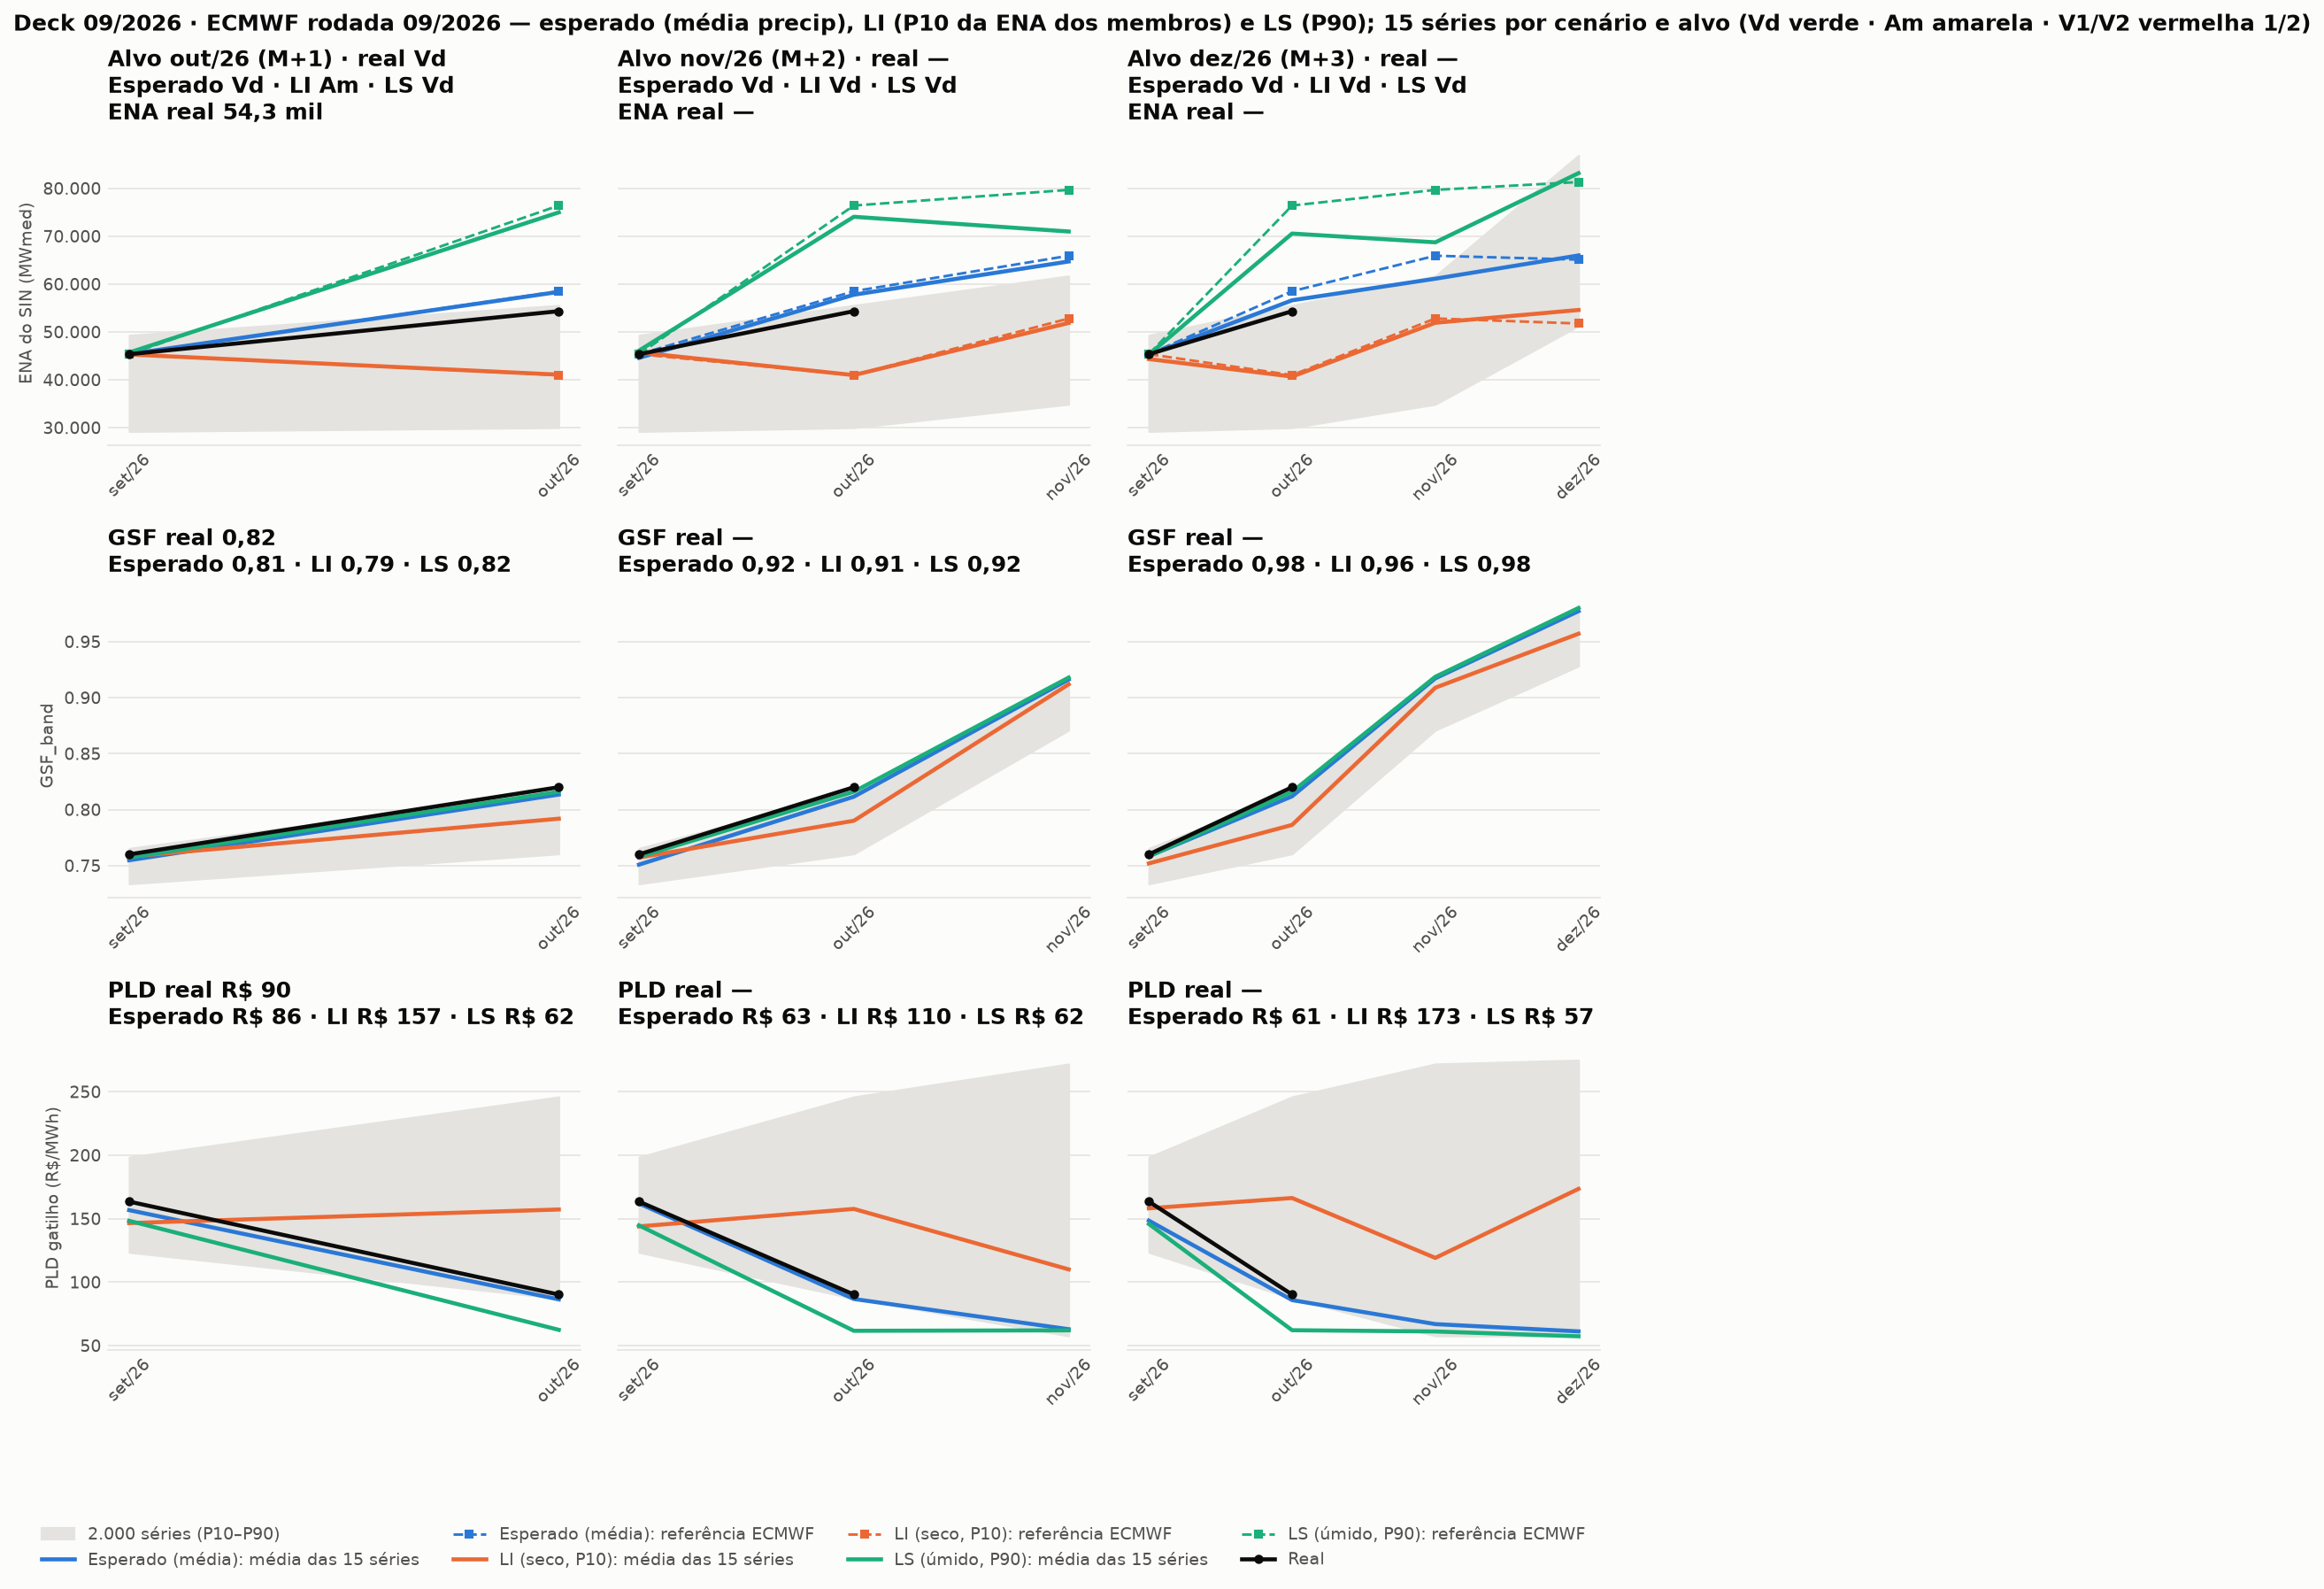

In [8]:
ROTULOS = {"esp": "Esperado (média)", "li": "LI (seco, P10)", "ls": "LS (úmido, P90)"}
for dk in [d for d in decks if d.year == 2026]:
    pr, refs, t = cenarios[dk]
    alvos = list(t.alvo)
    cen = {ROTULOS[n]: {"referencia": ref, "escolhidas": {a: backtest._escolher(pr, ref, a, K, MV) for a in alvos},
                        "cores": dict(zip(t.alvo, t[f"cor_{n}"]))} for n, ref in refs.items()}
    caminho = graficos.trajetorias_cenarios(
        pr["ena"], pr["gsf"], pr["pld"], cen, base,
        f"Deck {dk.month:02d}/{dk.year} · ECMWF rodada {dk.month:02d}/{dk.year} — esperado (média precip), LI (P10 da ENA "
        "dos membros) e LS (P90); 15 séries por cenário e alvo (Vd verde · Am amarela · V1/V2 vermelha 1/2)",
        f"ecmwf/cenarios_li_ls/16_trajetorias_cenarios_deck_{dk.year}_{dk.month:02d}.png")
display(Image(caminho))